<a href="https://colab.research.google.com/github/25guptav-v/GenAi/blob/main/Practical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)

tokens = ["Hey", "How", "are","you"]
seq_len = len(tokens)
#Let's define embedding dimension (d_model) and projection dimensions (d_k, d_v)
d_model = 16
d_k = 8
d_v = 8
#2. Initialize toy embeddings for our tokens
embeddings = torch.randn(seq_len, d_model)
print("Input embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb[:4].tolist()}...(dimension: {d_model})")
#3 Define project weights
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)
# Compute Q, K, V
Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)

Input embeddings (Hidden States):
Hey: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]...(dimension: 16)
How: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]...(dimension: 16)
are: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]...(dimension: 16)
you: [-0.9138230085372925, -0.6581372618675232, 0.07802387326955795, 0.5258087515830994]...(dimension: 16)
Queries (Q) Shape: torch.Size([4, 8])
Keys (K) Shape: torch.Size([4, 8])
Values (V) Shape: torch.Size([4, 8])


In [5]:
#4. Raw Attention Score (Q * k^T)
atten_scores = torch.matmul(Q, K.transpose(0,1))
#5. Attention Distribution (Softmax)
atten_distribution = F.softmax(atten_scores, dim=-1)
print("Raw Attention Scores (Q * K^T):\n", atten_scores.numpy())
print("\nAttention Distribution (Softmaxed):\n", atten_distribution.numpy())

Raw Attention Scores (Q * K^T):
 [[ 21.636702  -21.297962   -1.7726326 -16.491356 ]
 [-90.908554   54.393482   60.088253   -9.9405775]
 [ -7.82681    54.974274   -3.4535131  12.55924  ]
 [ -5.877186   34.083015   21.080673    3.512283 ]]

Attention Distribution (Softmaxed):
 [[1.0000000e+00 2.2579446e-19 6.8148348e-11 2.7618126e-17]
 [0.0000000e+00 3.3522327e-03 9.9664778e-01 3.8495204e-31]
 [5.3190781e-28 1.0000000e+00 4.2182679e-26 3.7965217e-19]
 [4.4208333e-18 9.9999774e-01 2.2550364e-06 5.2880890e-14]]


In [6]:
#6. Calculate Final Attention Output Vectors
attention_output = torch.matmul(atten_distribution, V)
print("Final Attention Output Shape:\n", attention_output.shape)
for token, val in zip(tokens, attention_output):
    print(f"{token} attention vector: {val.tolist()}")

Final Attention Output Shape:
 torch.Size([4, 8])
Hey attention vector: [-4.519536018371582, -5.458115577697754, 1.4559129476547241, -10.491732597351074, 2.3393959999084473, 3.1354081630706787, 0.5133363604545593, 0.3840251564979553]
How attention vector: [-5.301782608032227, 2.3479011058807373, 3.327111005783081, 3.076202869415283, 1.4235764741897583, -1.8251417875289917, -2.165999412536621, 2.7394859790802]
are attention vector: [4.109902381896973, -8.193885803222656, 1.54173743724823, 2.214273691177368, 1.8528388738632202, 1.5154098272323608, -2.423623561859131, 1.879045009613037]
you attention vector: [4.1098809242248535, -8.193861961364746, 1.5417414903640747, 2.214275598526001, 1.8528379201889038, 1.5154021978378296, -2.4236228466033936, 1.87904691696167]


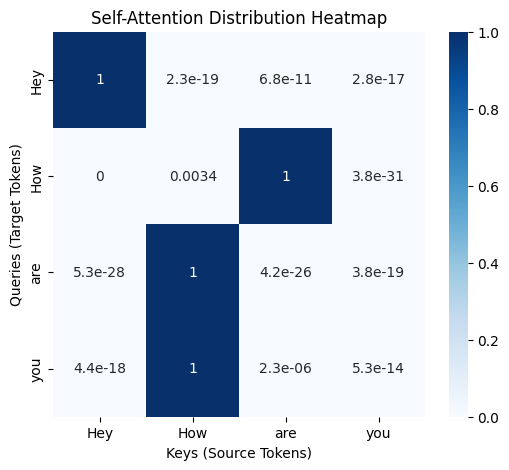

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    atten_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin = 0,
    vmax =1
)
plt.title("Self-Attention Distribution Heatmap")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.show()

In [8]:
# Explicitly show the math for step-by-step computation
for i, q_token in enumerate(tokens):
  print(f"\n--- Calculations for Query token: '{q_token}' ---")
  q_vec = Q[i]
  #1. Compute raw dot product with all keys
  raw_scores = []
  scaled_scores = []
  for j, k_token in enumerate(tokens):
    k_vec = K[j]
    dot_product = torch.dot(q_vec, k_vec).item()
    scaled_dot_product = dot_product / (d_k ** 0.5)
    raw_scores.append(dot_product)
    scaled_scores.append(scaled_dot_product)
    print(f"Key '{k_token}': Raw Dot Product = {dot_product:.4f}, Scaled (/{d_k ** 0.5:.2f}) = {scaled_dot_product:.4f}")

  #2 Compute Softmax manually to show distribution
  exp_scores = np.exp(scaled_scores)
  sum_exp = np.sum(exp_scores)
  probabilities = exp_scores / sum_exp

  print("\n--- Softmax Distribution ---")
  for j, k_token in enumerate(tokens):
    print(f" {k_token}:exp({scaled_scores[j]:.4f}) / sum_exp = {probabilities[j]:.4e}")


--- Calculations for Query token: 'Hey' ---
Key 'Hey': Raw Dot Product = 21.6367, Scaled (/2.83) = 7.6497
Key 'How': Raw Dot Product = -21.2980, Scaled (/2.83) = -7.5300
Key 'are': Raw Dot Product = -1.7726, Scaled (/2.83) = -0.6267
Key 'you': Raw Dot Product = -16.4914, Scaled (/2.83) = -5.8306

--- Softmax Distribution ---
 Hey:exp(7.6497) / sum_exp = 9.9974e-01
 How:exp(-7.5300) / sum_exp = 2.5552e-07
 are:exp(-0.6267) / sum_exp = 2.5437e-04
 you:exp(-5.8306) / sum_exp = 1.3979e-06

--- Calculations for Query token: 'How' ---
Key 'Hey': Raw Dot Product = -90.9086, Scaled (/2.83) = -32.1410
Key 'How': Raw Dot Product = 54.3935, Scaled (/2.83) = 19.2310
Key 'are': Raw Dot Product = 60.0883, Scaled (/2.83) = 21.2444
Key 'you': Raw Dot Product = -9.9406, Scaled (/2.83) = -3.5145

--- Softmax Distribution ---
 Hey:exp(-32.1410) / sum_exp = 5.7619e-24
 How:exp(19.2310) / sum_exp = 1.1780e-01
 are:exp(21.2444) / sum_exp = 8.8220e-01
 you:exp(-3.5145) / sum_exp = 1.5592e-11

--- Calculatio

In [9]:

# Define multi-head attention dimensions
num_heads = 2
d_k_head = 8
d_v_head = 8

#Initialize MHA weights
W_q_mha = torch.randn(d_model, d_model)
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)
#1 Linear Projections
Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)
#2 Reshape to split into heads
Q_Split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
K_Split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
V_Split = V_mha.view(seq_len, num_heads, d_v_head).transpose(0,1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_Split.shape)
print("Split Keys Shape (num_heads, seq_len, d_k_head):", K_Split.shape)
print("Split Values Shape (num_heads, seq_len, d_v_head):", V_Split.shape)

Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 4, 8])
Split Keys Shape (num_heads, seq_len, d_k_head): torch.Size([2, 4, 8])
Split Values Shape (num_heads, seq_len, d_v_head): torch.Size([2, 4, 8])


In [10]:
#3 Compute attention score & attention for each head independently
scores = torch.matmul(Q_Split, K_Split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_Split)
#4 Concatinate head outputs
concat_output = head_outputs.transpose(0, 1).contiguous().view(seq_len, d_model)
#5 Final linear projection
final_output = torch.matmul(concat_output, W_o)
print("Attention Distribution Shape (for all heads):", distributions.shape)
print("Concatenated Output Shape:", concat_output.shape)
print("Final Multi-head Attention Output Shape:", final_output.shape)

Attention Distribution Shape (for all heads): torch.Size([2, 4, 4])
Concatenated Output Shape: torch.Size([4, 16])
Final Multi-head Attention Output Shape: torch.Size([4, 16])


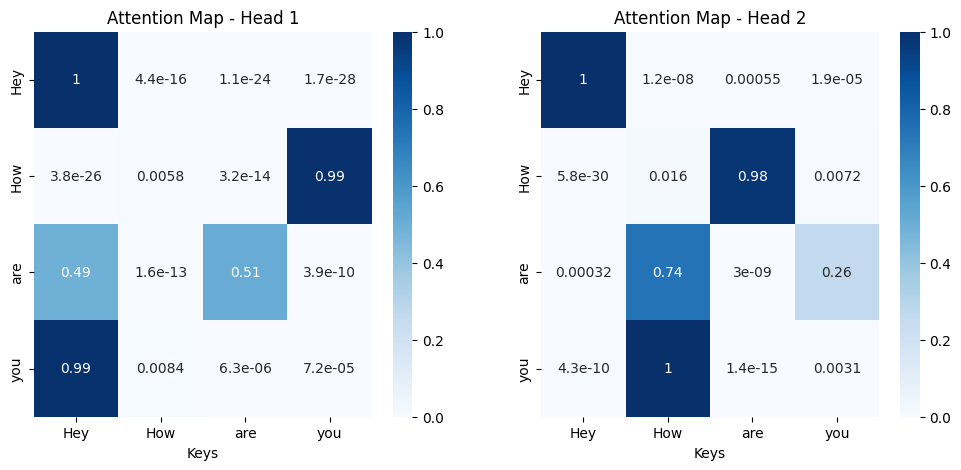

In [11]:
# Let's visualize the attention maps for both heads side-by-side
fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))
for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(),
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmax=1,
        vmin=0,
        ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h+1}")
    axes[h].set_xlabel("Keys")